 Week 4: Cohort, Discount 

**Objective:** understand how customers behave over time (cohorts), how discounts affect sales and profit, and which products are both big sellers and real earners.

**Data:** superstore_cleaned.csv

In [1]:
import os
import pandas as pd
import numpy as np
import plotly.express as px

px.defaults.template = "plotly_white"
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 200
os.makedirs("charts", exist_ok=True)

df = pd.read_csv("../02_Cleaned_Data/superstore_cleaned.csv", parse_dates=["order_date", "ship_date"])
print(df.shape)   # expect (9993, 29)

def save_sheets(sheets, path="analysis.xlsx"):
    """Add sheets to analysis.xlsx without deleting the sheets from earlier weeks."""
    exists = os.path.exists(path)
    kwargs = {"mode": "a", "if_sheet_exists": "replace"} if exists else {"mode": "w"}
    with pd.ExcelWriter(path, engine="openpyxl", **kwargs) as w:
        for name, table in sheets.items():
            table.to_excel(w, sheet_name=name, index=False)

(9993, 29)


# Part A: Cohort analysis

## 1. Define the cohorts
A **cohort** is a group of customers who made their first purchase in the same month. For each order we need three things:
- `order_month`: the month of the order
- `cohort_month`: the month of that customer's **first** order
- `period`: how many months after the first purchase this order happened (0 = the first month)

**Caveat:** the data starts in January 2014, so customers who first appear in 2014 may have bought from this company before the data begins. The 2014 cohorts are therefore partly "existing customers", not only new ones.

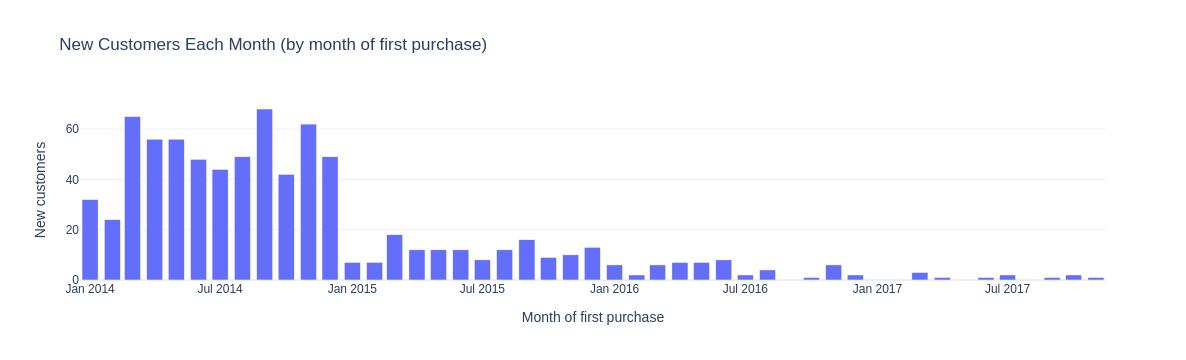

Total customers: 793
cohort_year
2014    595
2015    136
2016     51
2017     11
Name: new customers per year, dtype: int64


In [2]:
df["order_month"] = df["order_date"].dt.to_period("M")
df["cohort_month"] = df.groupby("customer_id")["order_month"].transform("min")
df["period"] = (df["order_month"] - df["cohort_month"]).apply(lambda x: x.n)
df["cohort_year"] = df["cohort_month"].dt.year
df["year"] = df["order_date"].dt.year

new_customers = (df.drop_duplicates("customer_id").groupby("cohort_month").size()
                   .rename("new_customers").reset_index())
new_customers["cohort_month"] = new_customers["cohort_month"].astype(str)

fig_new = px.bar(new_customers, x="cohort_month", y="new_customers",
                 title="New Customers Each Month (by month of first purchase)",
                 labels={"cohort_month": "Month of first purchase", "new_customers": "New customers"})
fig_new.show()

print("Total customers:", new_customers.new_customers.sum())
print(df.drop_duplicates("customer_id").groupby("cohort_year").size().rename("new customers per year"))

**Finding (Question 1: how many new customers joined each month?):** the business gained between 24 and 68 new customers every month during 2014 (595 in the year), then the numbers fall sharply: **136 in 2015, 51 in 2016 and only 11 in 2017**. In 2017 no customer joined in January, February, May, August or December. Customer acquisition has almost stopped, even though sales kept growing.

## 2. The cohort retention table
For each cohort we count how many customers placed an order in each later month, and divide by the cohort size. Month 0 is always 100%. Cells are left empty when the data has not reached that month yet. Only the 24 cohorts of 2014 and 2015 are drawn, because the 2016 and 2017 cohorts are too small (1 to 8 customers) to give stable percentages.

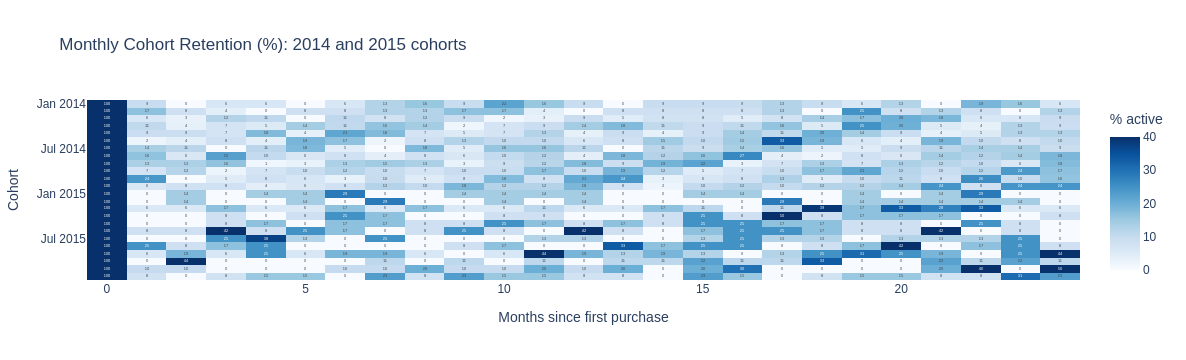

In [3]:
cohort_counts = (df.groupby(["cohort_month", "period"]).customer_id.nunique()
                   .unstack(fill_value=0))
last_month = df["order_month"].max()
max_period = pd.Series({c: (last_month - c).n for c in cohort_counts.index})

retention = cohort_counts.div(cohort_counts[0], axis=0) * 100
for p in retention.columns:
    retention.loc[max_period < p, p] = np.nan      # months the data has not reached yet

heat = retention.loc[:"2015-12", 0:24].copy()
heat.index = heat.index.astype(str)

fig_heat = px.imshow(heat, text_auto=".0f", aspect="auto", color_continuous_scale="Blues", zmin=0, zmax=40,
                     title="Monthly Cohort Retention (%): 2014 and 2015 cohorts",
                     labels={"x": "Months since first purchase", "y": "Cohort", "color": "% active"})
fig_heat.show()

**How to read it:** each row is a cohort, each column is months after the first purchase. A value of 12 in row "2014-03", column 6 means 12% of the customers who first bought in March 2014 ordered again in September 2014.

**Finding:** apart from month 0, about 95% of the cells are 25% or lower, and the typical (median) cell is about 10%. Month-to-month retention looks low. This does not mean customers leave: the next section shows they simply do not buy every month.

## 3. Average retention and the real picture
Two views: the average monthly retention curve over all cohorts, and an annual view (the share of each starting group that bought again in each calendar year).

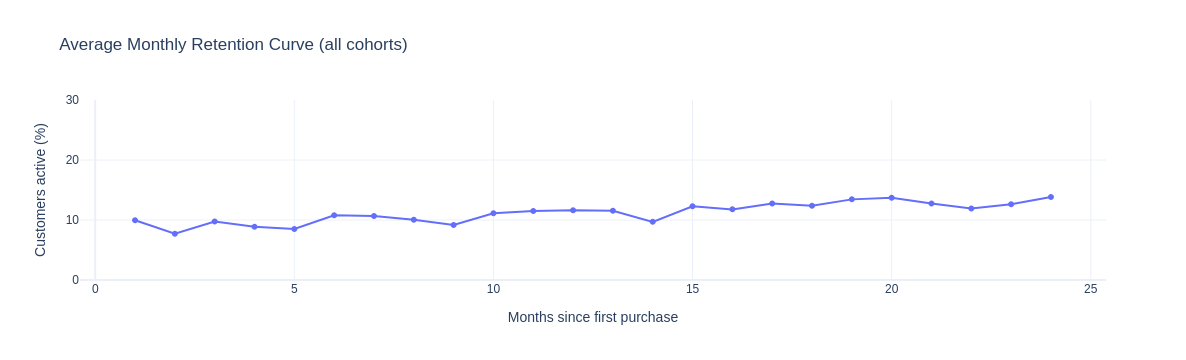

,months_since_first_purchase,avg_retention_pct
0,1,9.96
2,3,9.75
5,6,10.80
11,12,11.64
23,24,13.82


In [4]:
curve = []
for p in range(1, 25):
    ok = max_period[max_period >= p].index
    curve.append({"months_since_first_purchase": p,
                  "avg_retention_pct": cohort_counts.loc[ok, p].sum() / cohort_counts.loc[ok, 0].sum() * 100})
curve = pd.DataFrame(curve)

fig_curve = px.line(curve, x="months_since_first_purchase", y="avg_retention_pct", markers=True,
                    title="Average Monthly Retention Curve (all cohorts)",
                    labels={"months_since_first_purchase": "Months since first purchase",
                            "avg_retention_pct": "Customers active (%)"})
fig_curve.update_yaxes(range=[0, 30])
fig_curve.show()
display(curve[curve.months_since_first_purchase.isin([1, 3, 6, 12, 24])])

In [5]:
# Annual view: customers active in each calendar year, by the year of their first purchase
active = df.groupby(["cohort_year", "year"]).customer_id.nunique().unstack()
active_pct = active.copy()
for cy in active.index:
    active_pct.loc[cy] = active.loc[cy] / active.loc[cy, cy] * 100
display(active)
display(active_pct.round(1))

# Ordering rhythm
orders_u = df.drop_duplicates("order_id").sort_values(["customer_id", "order_date"]).copy()
orders_u["gap_days"] = orders_u.groupby("customer_id")["order_date"].diff().dt.days
orders_per_cust = df.groupby("customer_id").order_id.nunique()
print("Median days between a customer's orders:", orders_u.gap_days.median())
print("Customers with 2 or more orders:", int((orders_per_cust >= 2).sum()), f"({(orders_per_cust >= 2).mean() * 100:.1f}%)")
print("Average number of months with an order, per customer:", round(df.groupby("customer_id").order_month.nunique().mean(), 1))

year,2014,2015,2016,2017
cohort_year,,,,
2014,595.00,437.00,485.00,517.00
2015,NaN,136.00,102.00,120.00
2016,NaN,NaN,51.00,45.00
2017,NaN,NaN,NaN,11.00


year,2014,2015,2016,2017
cohort_year,,,,
2014,100.00,73.40,81.50,86.90
2015,NaN,100.00,75.00,88.20
2016,NaN,NaN,100.00,88.20
2017,NaN,NaN,NaN,100.00


Median days between a customer's orders: 128.5
Customers with 2 or more orders: 781 (98.5%)
Average number of months with an order, per customer: 5.8


**Finding (Question 4: how does customer activity change after the first purchase?):**
- In any single month after the first purchase, only about **10%** of a cohort is active (10.0% in month 1, 9.7% in month 3, 10.8% in month 6). The curve is flat and even creeps up (11.6% at month 12, 13.8% at month 24). Customers do not fade away: they keep returning at a steady, occasional pace.
- The explanation is the ordering rhythm: the **median gap between a customer's orders is about 128 days** (about four months), so in a given month most customers are simply not due to buy.
- The annual view shows the real retention: of the 595 customers who started in 2014, **73% were active again in 2015, 82% in 2016 and 87% in 2017**. 98.5% of all customers (781 of 793) have placed at least two orders.
- **Conclusion:** this is a loyal customer base that buys a few times a year. Monthly retention is the wrong yardstick for it; annual activity is better.

## 4. Revenue by cohort

,cohort_month,sales,profit,customers
2,2014-03,"221,986.41","14,450.76",65
8,2014-09,"208,099.86","20,877.35",68
10,2014-11,"201,083.52","37,505.08",62
3,2014-04,"183,881.41","25,680.18",56
4,2014-05,"174,869.02","16,503.49",56


Top 5 cohorts share of total sales: 43.1 %


,cohort_year,customers,sales,profit,sales_share_pct
0,2014,595,"1,837,043.24","219,810.64",79.98
1,2015,136,"336,654.57","46,392.99",14.66
2,2016,51,"115,709.88","18,399.28",5.04
3,2017,11,"7,511.81","1,806.17",0.33


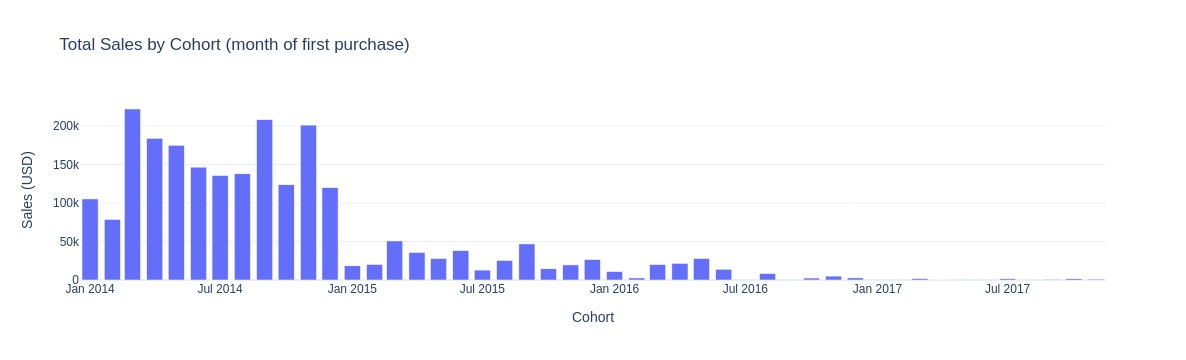

In [6]:
cohort_rev = df.groupby("cohort_month").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
cohort_rev = cohort_rev.merge(df.drop_duplicates("customer_id").groupby("cohort_month").size()
                              .rename("customers").reset_index(), on="cohort_month")
cohort_rev["cohort_month"] = cohort_rev["cohort_month"].astype(str)
top5 = cohort_rev.nlargest(5, "sales")
display(top5)
print("Top 5 cohorts share of total sales:", round(top5.sales.sum() / df.sales.sum() * 100, 1), "%")

by_year = df.groupby("cohort_year").agg(customers=("customer_id", "nunique"),
                                         sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
by_year["sales_share_pct"] = by_year.sales / by_year.sales.sum() * 100
display(by_year)

fig_cr = px.bar(cohort_rev, x="cohort_month", y="sales", title="Total Sales by Cohort (month of first purchase)",
                labels={"cohort_month": "Cohort", "sales": "Sales (USD)"})
fig_cr.show()

In [7]:
# New versus returning customers: where does each year's revenue come from?
df["is_first_month"] = df["order_month"] == df["cohort_month"]
nr = df.groupby(["year", "is_first_month"]).sales.sum().unstack()
nr.columns = ["returning_sales", "new_customer_sales"]
nr["new_customer_share_pct"] = nr.new_customer_sales / (nr.new_customer_sales + nr.returning_sales) * 100
nr = nr.reset_index()
display(nr)

,year,returning_sales,new_customer_sales,new_customer_share_pct
0,2014,"173,243.43","310,722.69",64.20
1,2015,"408,229.83","62,302.68",13.24
2,2016,"582,278.27","26,927.33",4.42
3,2017,"727,458.05","5,757.20",0.79


**Finding (Question 2: which cohort generated the most revenue?):** the **March 2014 cohort** generated the most revenue (**$221,986**), followed by September 2014 ($208,100) and November 2014 ($201,084). The top five cohorts, all from 2014, account for **43.1% of all sales**. By year, the **2014 cohort (595 customers) produced 80.0% of total sales** and 77% of profit, against 14.7% for 2015, 5.0% for 2016 and 0.3% for 2017.

**New versus returning:** new customers made 64% of 2014 sales, but only 13% in 2015, 4.4% in 2016 and **0.8% in 2017**. Almost all of the 2017 growth (+20%) came from customers the business already had.

## 5. Which cohorts repeat the most?
To compare cohorts fairly, we look at the **first 12 months** after each customer's first purchase, using only cohorts with at least 12 months of data.

,cohort_year,customers,avg_orders_first_12m,avg_sales_first_12m
0,2014,595,2.13,"1,037.74"
1,2015,136,2.26,"1,011.57"
2,2016,51,2.73,"1,607.41"


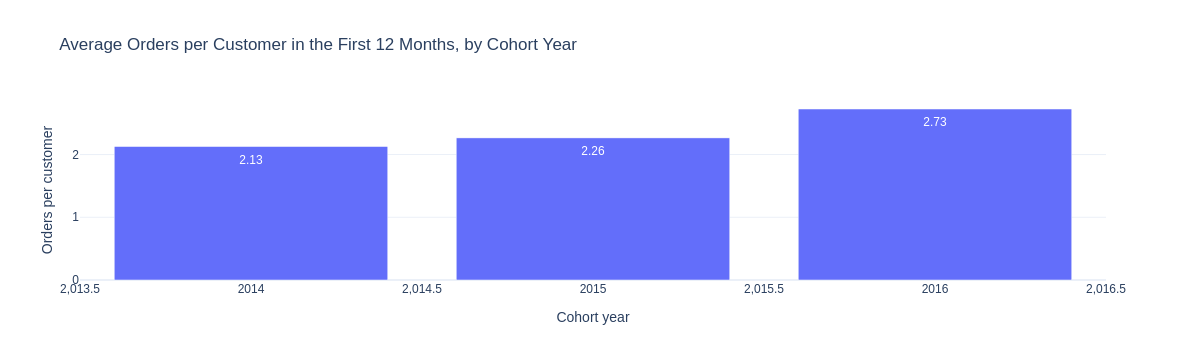

Customers (with 12+ months of data) who ordered again in a later month within 12 months: 70.8%


In [8]:
eligible = df[df["cohort_month"] <= last_month - 11]
first12 = eligible[eligible["period"] <= 11]
per_cust = first12.groupby(["cohort_year", "customer_id"]).agg(orders=("order_id", "nunique"),
                                                                sales=("sales", "sum")).reset_index()
first_year = per_cust.groupby("cohort_year").agg(customers=("customer_id", "count"),
                                                  avg_orders_first_12m=("orders", "mean"),
                                                  avg_sales_first_12m=("sales", "mean")).reset_index()
display(first_year)

fig_fy = px.bar(first_year, x="cohort_year", y="avg_orders_first_12m", text_auto=".2f",
                title="Average Orders per Customer in the First 12 Months, by Cohort Year",
                labels={"cohort_year": "Cohort year", "avg_orders_first_12m": "Orders per customer"})
fig_fy.show()

returned = df[(df.period >= 1) & (df.period <= 12)].customer_id.unique()
elig_customers = df[df["cohort_month"] <= last_month - 12].customer_id.unique()
share = len(set(returned) & set(elig_customers)) / len(elig_customers) * 100
print(f"Customers (with 12+ months of data) who ordered again in a later month within 12 months: {share:.1f}%")

**Finding (Question 3: which cohorts have stronger repeat purchasing?):** the newer the cohort, the more it buys in its first year: customers who started in 2014 placed **2.13 orders** in their first 12 months, the 2015 group 2.26, and the **2016 group 2.73 orders and about $1,607 in sales**, against roughly $1,040 for the 2014 group. The newer cohorts are small (51 customers in 2016), so treat this as an encouraging sign, not a proven trend. About **71%** of customers ordered again in a later month within their first year.

## Cohort questions: summary of answers
1. **New customers per month:** 24 to 68 a month in 2014, falling to 136 in all of 2015, 51 in 2016 and 11 in 2017.
2. **Cohort with the most revenue:** March 2014 ($221,986). The 2014 cohort as a whole gives 80% of sales.
3. **Stronger repeat behaviour:** the 2016 cohort (2.73 orders in the first year against 2.13 for 2014), though it is small.
4. **Activity after the first purchase:** about 10% of a cohort is active in any given month, steadily; 73% to 87% of the 2014 cohort is active in each later year. Customers buy roughly every four months.

# Part B: Discount analysis

## 6. Discount bands: sales and profit

,discount_band,lines,sales,profit,avg_line_sales,avg_units_per_line,pct_lines_losing,margin_pct
0,0%,4798,"1,087,908.47","320,987.60",226.74,3.81,0.00,29.51
1,1-10%,94,"54,369.35","9,029.18",578.40,3.97,4.26,16.61
2,11-20%,3709,"792,152.89","91,756.30",213.58,3.74,13.99,11.58
3,21-30%,226,"102,945.28","-10,357.22",455.51,3.75,91.59,-10.06
4,31-40%,233,"130,911.24","-25,448.19",561.85,3.82,88.84,-19.44
5,41-50%,77,"64,403.51","-22,999.54",836.41,3.71,100.00,-35.71
6,51-80%,856,"64,228.74","-76,559.05",75.03,3.91,100.00,-119.20


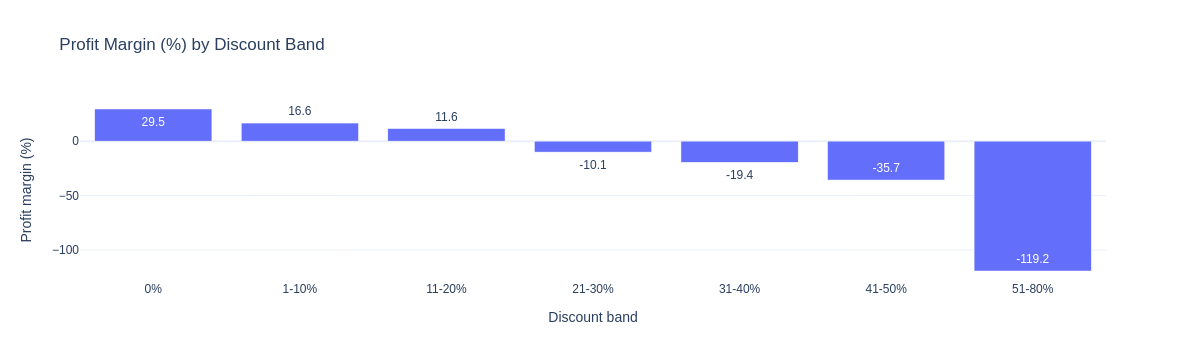

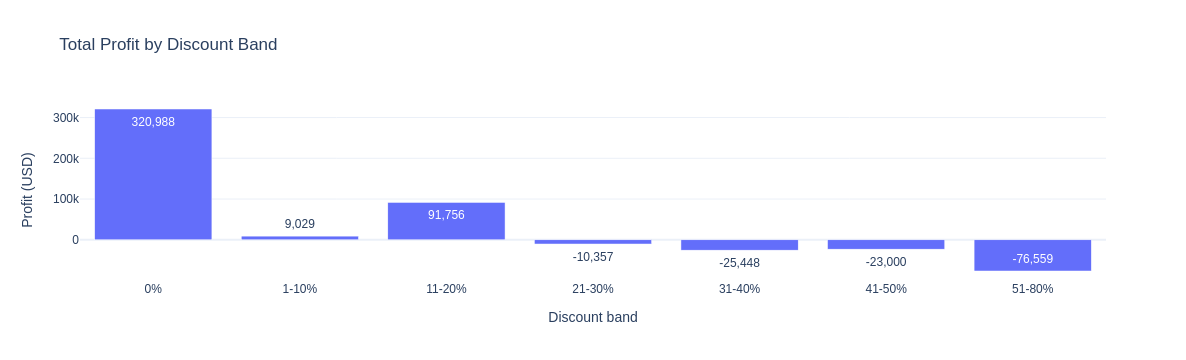

{'discount': 1.0, 'sales': -0.028, 'profit': -0.219, 'quantity': 0.009}
Lines with a discount above 20%: 1392 (13.9% of lines)
Their total profit: -135364.0 | share of them that lose money: 96.8 %


In [9]:
bins = [-0.01, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 1.00]
labels = ["0%", "1-10%", "11-20%", "21-30%", "31-40%", "41-50%", "51-80%"]
df["discount_band"] = pd.cut(df["discount"], bins=bins, labels=labels)

bands = df.groupby("discount_band", observed=True).agg(
    lines=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"),
    avg_line_sales=("sales", "mean"), avg_units_per_line=("quantity", "mean"),
    pct_lines_losing=("is_loss", "mean")).reset_index()
bands["margin_pct"] = bands.profit / bands.sales * 100
bands["pct_lines_losing"] = bands["pct_lines_losing"] * 100
display(bands)

fig_bm = px.bar(bands, x="discount_band", y="margin_pct", text_auto=".1f",
                title="Profit Margin (%) by Discount Band",
                labels={"discount_band": "Discount band", "margin_pct": "Profit margin (%)"})
fig_bm.show()

fig_bp = px.bar(bands, x="discount_band", y="profit", text_auto=",.0f",
                title="Total Profit by Discount Band",
                labels={"discount_band": "Discount band", "profit": "Profit (USD)"})
fig_bp.show()

print(df[["discount", "sales", "profit", "quantity"]].corr().loc["discount"].round(3).to_dict())
over20 = df[df.discount > 0.20]
print("Lines with a discount above 20%:", len(over20), f"({len(over20) / len(df) * 100:.1f}% of lines)")
print("Their total profit:", round(over20.profit.sum(), 2), "| share of them that lose money:", round(over20.is_loss.mean() * 100, 1), "%")

**Finding (Question 2: does higher discounting increase sales?):** there is no sign of it. The average number of units per order line stays at **3.7 to 4.0 in every band**, from no discount to 80% off, and the correlation between discount and line sales is almost zero (-0.03). The data cannot show whether discounts win extra orders overall (we do not know what would have happened without them), but they do not make individual orders bigger.

**Finding (Question 3: does higher discounting reduce profit?):** yes, strongly. The margin falls from **29.5%** with no discount to 16.6% (1-10%) and **11.6% (11-20%)**, and then turns negative: **-10.1% at 21-30%, -19.4% at 31-40%, -35.7% at 41-50% and -119% at 51-80%**. 92% of the lines in the 21-30% band and every line above 40% lose money. In total, the **1,392 lines discounted above 20% (14% of all lines) lost $135,364**, which is equal to 47% of the profit the whole business made ($286,409). Discounts up to 20% are still profitable, so about 20% is the break-even limit.

## 7. Which products and sub-categories get the highest discounts?

,product_name,avg_discount,lines,sales,profit
696,GBC Plasticlear Binding Covers,0.73,7,68.88,-68.42
1301,"Premier Elliptical Ring Binder, Black",0.64,9,526.61,-201.51
1627,Wilson Jones Custom Binder Spines & Labels,0.63,7,41.34,-19.69
57,Acco D-Ring Binder w/DublLock,0.62,9,235.18,-102.84
239,Avery Durable Slant Ring Binders,0.62,5,51.48,-23.76
271,"Avery Triangle Shaped Sheet Lifters, Black, 2/...",0.62,6,25.83,-4.92
255,Avery Hidden Tab Dividers for Binding Systems,0.61,7,31.59,-7.03
924,Insertable Tab Indexes For Data Binders,0.60,5,17.49,-4.83
266,Avery Reinforcements for Hole-Punch Pages,0.57,8,28.51,-16.14
925,Insertable Tab Post Binder Dividers,0.57,8,66.57,-39.70


,sub_category,avg_discount,lines,profit,pct_lines_over_20
3,Binders,0.37,1523,"30,221.76",40.25
11,Machines,0.31,115,"3,384.76",46.09
16,Tables,0.26,319,"-17,725.48",55.17
4,Bookcases,0.21,228,"-3,472.56",30.70
5,Chairs,0.17,616,"26,602.23",25.49
1,Appliances,0.17,466,"18,138.01",14.38
6,Copiers,0.16,68,"55,617.82",13.24
13,Phones,0.15,889,"44,515.73",12.26
9,Furnishings,0.14,957,"13,059.14",14.42
8,Fasteners,0.08,217,949.52,0.00


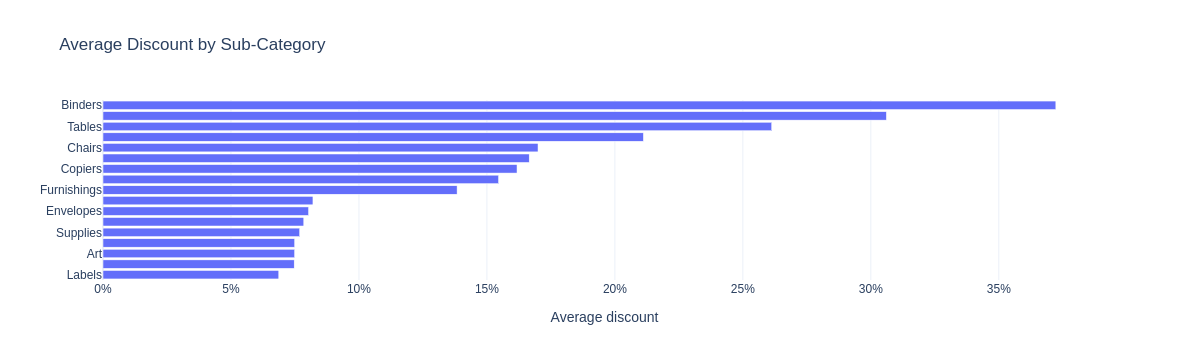

In [10]:
prod_disc = df.groupby("product_name").agg(avg_discount=("discount", "mean"), lines=("sales", "size"),
                                           sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
top_disc = prod_disc[prod_disc.lines >= 5].nlargest(10, "avg_discount")
display(top_disc)

sub_disc = df.groupby("sub_category").agg(avg_discount=("discount", "mean"), lines=("sales", "size"),
                                          profit=("profit", "sum")).reset_index()
sub_disc["pct_lines_over_20"] = (df.assign(o=df.discount > 0.20).groupby("sub_category").o.mean() * 100).values
sub_disc = sub_disc.sort_values("avg_discount", ascending=False)
display(sub_disc)

fig_sd = px.bar(sub_disc.sort_values("avg_discount"), x="avg_discount", y="sub_category", orientation="h",
                title="Average Discount by Sub-Category", labels={"avg_discount": "Average discount", "sub_category": ""})
fig_sd.update_xaxes(tickformat=".0%")
fig_sd.show()

**Finding (Question 1: which products receive the highest discounts?):** among products with at least five order lines, the highest average discounts are on **binder accessories**: GBC Plasticlear Binding Covers (73%), Premier Elliptical Ring Binder (64%), Wilson Jones Binder Spines (63%) and Acco D-Ring Binder (62%). Every one of these ten products lost money. By sub-category, **Binders** (average 37%), **Machines** (31%), **Tables** (26%) and **Bookcases** (21%) are discounted the most, while Paper, Art, Storage, Labels and Supplies average 7% to 8%. 55% of Tables lines and 46% of Machines lines are discounted by more than 20%, which helps explain why Tables loses $17,725 and Machines earns only a 1.8% margin.

## 8. Which categories and regions are most affected?

,category,avg_discount,lines,pct_lines_over_20,profit_lines_over_20,profit_lines_up_to_20
0,Furniture,0.17,2120,25.52,"-54,465.70","72,929.03"
1,Office Supplies,0.16,6026,11.28,"-47,140.14","169,630.94"
2,Technology,0.13,1847,9.26,"-33,758.16","179,213.11"


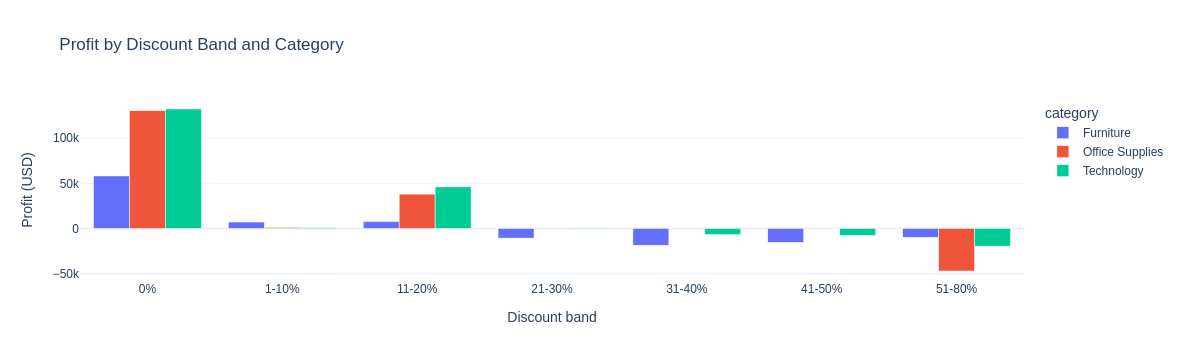

,region,avg_discount,pct_lines_over_20,profit_lines_over_20
0,Central,0.24,27.68,"-52,392.27"
1,East,0.15,16.16,"-42,076.55"
2,South,0.15,10.56,"-24,880.48"
3,West,0.11,3.68,"-16,014.69"


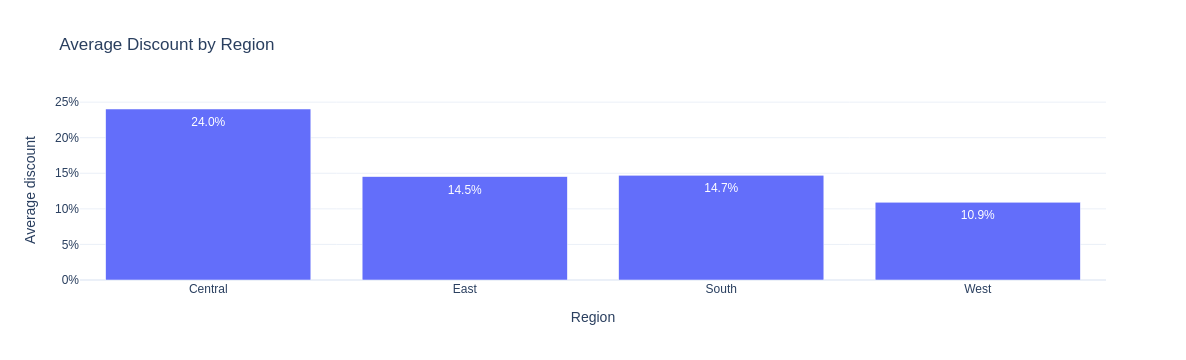

In [11]:
cat_disc = df.groupby("category").agg(avg_discount=("discount", "mean"), lines=("sales", "size")).reset_index()
cat_disc["pct_lines_over_20"] = (df.assign(o=df.discount > 0.20).groupby("category").o.mean() * 100).values
cat_disc["profit_lines_over_20"] = df[df.discount > 0.20].groupby("category").profit.sum().values
cat_disc["profit_lines_up_to_20"] = df[df.discount <= 0.20].groupby("category").profit.sum().values
display(cat_disc)

cat_band = df.groupby(["category", "discount_band"], observed=True).profit.sum().reset_index()
fig_cb = px.bar(cat_band, x="discount_band", y="profit", color="category", barmode="group",
                title="Profit by Discount Band and Category",
                labels={"discount_band": "Discount band", "profit": "Profit (USD)"})
fig_cb.show()

reg_disc = df.groupby("region").agg(avg_discount=("discount", "mean")).reset_index()
reg_disc["pct_lines_over_20"] = (df.assign(o=df.discount > 0.20).groupby("region").o.mean() * 100).values
reg_disc["profit_lines_over_20"] = df[df.discount > 0.20].groupby("region").profit.sum().values
display(reg_disc)

fig_rd = px.bar(reg_disc, x="region", y="avg_discount", text_auto=".1%",
                title="Average Discount by Region", labels={"region": "Region", "avg_discount": "Average discount"})
fig_rd.update_yaxes(tickformat=".0%")
fig_rd.show()

**Finding (Question 4: which categories are most affected?):**
- **Furniture** is hit hardest: 25.5% of its lines are discounted above 20%, and those lines lost **$54,466**, while its other lines earned $72,929. The deep discounts wipe out about **75% of the profit Furniture would otherwise make**, which explains its 2.5% margin.
- **Office Supplies** has fewer heavy discounts (11.3% of lines), but all of them are at 51% or more, mostly on Binders (613 of about 680 lines), and they lost $47,140.
- **Technology** has the lowest share of heavily discounted lines (9.3%) but still lost $33,758 on them.

**Regions:** **Central** gives by far the biggest discounts: an average of 24% against 11% in the West, and 27.7% of its lines are discounted above 20% (West: 3.7%). Central's heavily discounted lines lost $52,392. This is the most likely reason for Central's weak 7.9% margin found in Week 2.

## Discount questions: summary of answers
1. **Highest discounts:** binder accessories and other Binders products at the product level; Binders, Machines, Tables and Bookcases at sub-category level.
2. **Does higher discounting increase sales?** No evidence: units per line are about the same (3.7 to 4.0) at every discount level.
3. **Does higher discounting reduce profit?** Yes. Margin goes from 29.5% (no discount) to negative above 20%. Lines over 20% lost $135,364.
4. **Categories most affected:** Furniture most (loses 75% of its potential profit), then Office Supplies and Technology. Central is the most affected region.

# Part C: Profitability analysis

## 9. Sales versus profit: four product groups
Each product is placed in one of four groups, to separate products that bring revenue from products that bring profit.

**Logic:** thresholds are the **median** product sales ($315.93) and the **median** product profit ($44.82) across the 1,850 products. A product is "High sales" if its total sales are at or above the median sales, and "High profit" if its total profit is at or above the median profit. Medians split the products into two equal halves on each measure, and they are not distorted by the very large products.

Median product sales: 315.93 | median product profit: 44.82


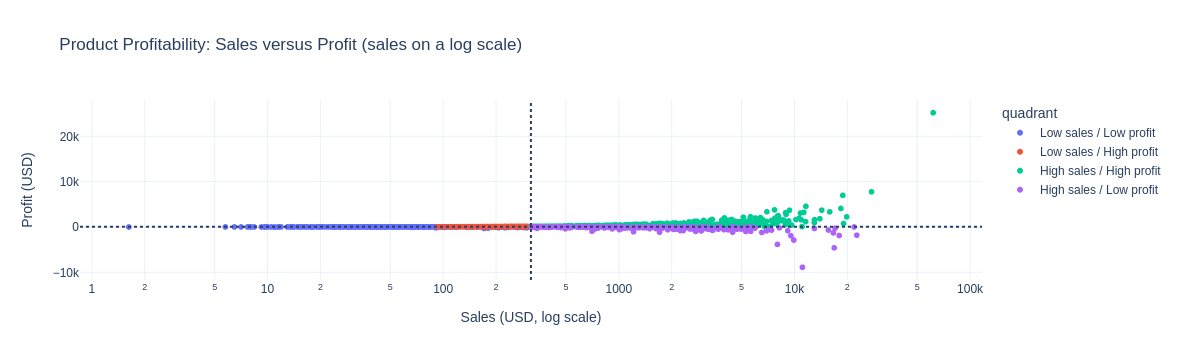

In [12]:
prod = df.groupby(["product_name", "category", "sub_category"]).agg(sales=("sales", "sum"),
                                                                    profit=("profit", "sum")).reset_index()
sales_med, profit_med = prod.sales.median(), prod.profit.median()
print(f"Median product sales: {sales_med:,.2f} | median product profit: {profit_med:,.2f}")

def quadrant(r):
    if r.sales >= sales_med and r.profit >= profit_med: return "High sales / High profit"
    if r.sales >= sales_med and r.profit <  profit_med: return "High sales / Low profit"
    if r.sales <  sales_med and r.profit >= profit_med: return "Low sales / High profit"
    return "Low sales / Low profit"

prod["quadrant"] = prod.apply(quadrant, axis=1)

fig_q = px.scatter(prod, x="sales", y="profit", color="quadrant", hover_name="product_name", log_x=True,
                   title="Product Profitability: Sales versus Profit (sales on a log scale)",
                   labels={"sales": "Sales (USD, log scale)", "profit": "Profit (USD)"})
fig_q.add_hline(y=profit_med, line_dash="dot")
fig_q.add_vline(x=sales_med, line_dash="dot")
fig_q.show()

,quadrant,products,sales,profit,loss_making,products_pct,sales_share_pct,profit_share_pct
0,High sales / High profit,673,"1,573,502.12","332,719.44",0,36.38,68.50,116.17
1,High sales / Low profit,252,"613,464.49","-72,632.44",198,13.62,26.71,-25.36
2,Low sales / High profit,252,"48,950.09","17,720.67",0,13.62,2.13,6.19
3,Low sales / Low profit,673,"61,002.78","8,601.40",103,36.38,2.66,3.00


category,Furniture,Office Supplies,Technology
quadrant,,,
High sales / High profit,141,277,255
High sales / Low profit,125,65,62
Low sales / High profit,34,195,23
Low sales / Low profit,80,521,72


,product_name,sales,profit
475,Cubify CubeX 3D Printer Double Head Print,"11,099.96","-8,879.97"
985,Lexmark MX611dhe Monochrome Laser Printer,"16,829.90","-4,589.97"
476,Cubify CubeX 3D Printer Triple Head Print,"7,999.98","-3,839.99"
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,"9,917.64","-2,876.12"
376,Bush Advantage Collection Racetrack Conference...,"9,544.73","-1,934.40"
683,GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17"
444,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48","-1,811.08"
1043,Martin Yale Chadless Opener Electric Letter Op...,"16,656.20","-1,299.18"


,product_name,sales,profit
1720,Xerox 1933,294.72,138.52
181,Avery 475,266.40,133.20
1325,"REDIFORM Incoming/Outgoing Call Register, 11"" ...",281.89,127.60
1059,Maxell DVD-RAM Discs,296.64,127.56
232,"Avery Address/Shipping Labels for Typewriters,...",277.38,126.68


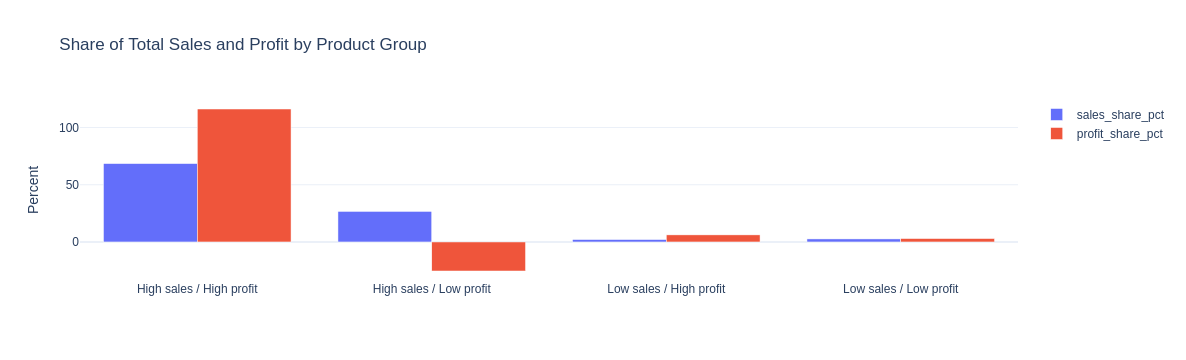

In [13]:
quad = prod.groupby("quadrant").agg(products=("product_name", "count"), sales=("sales", "sum"),
                                    profit=("profit", "sum"),
                                    loss_making=("profit", lambda s: int((s < 0).sum()))).reset_index()
quad["products_pct"] = quad.products / quad.products.sum() * 100
quad["sales_share_pct"] = quad.sales / quad.sales.sum() * 100
quad["profit_share_pct"] = quad.profit / quad.profit.sum() * 100
display(quad)

display(prod.groupby(["quadrant", "category"]).size().unstack())

hs_lp = prod[prod.quadrant == "High sales / Low profit"].nsmallest(8, "profit")
display(hs_lp[["product_name", "sales", "profit"]])
display(prod[prod.quadrant == "Low sales / High profit"].nlargest(5, "profit")[["product_name", "sales", "profit"]])

fig_qs = px.bar(quad, x="quadrant", y=["sales_share_pct", "profit_share_pct"], barmode="group",
                title="Share of Total Sales and Profit by Product Group",
                labels={"quadrant": "", "value": "Percent", "variable": ""})
fig_qs.show()

**Finding:**
- **High sales / High profit: 673 products (36%)** produce 68.5% of sales and more than all of the profit (116%, because other groups lose money). These are the products to protect.
- **High sales / Low profit: 252 products (14%)** produce **26.7% of sales but lose $72,632 in total**, and 198 of them lose money individually. These are the products that look good in a sales report but hurt profit: the Cubify 3D printers, the Lexmark MX611dhe laser printer, conference tables, the GBC DocuBind P400 and the Cisco TelePresence system. Furniture is over-represented (125 of the 252).
- **Low sales / High profit: 252 products (14%)** are small but efficient (mostly Office Supplies items). They give 2.1% of sales and 6.2% of profit.
- **Low sales / Low profit: 673 products (36%)** together give only 2.7% of sales and 3.0% of profit. This is a long tail that adds range complexity but little value.

# Part D: Findings, retention insights and recommendations

## Business findings
1. **Discounts above 20% destroy profit.** 1,392 lines (14% of all lines) lost $135,364, equal to 47% of total profit, and 97% of them lose money. Discounts did not make orders bigger.
2. **Central region over-discounts.** Its average discount is 24% against 11% in the West, and 27.7% of its lines exceed a 20% discount. This explains its weak margin (7.9%).
3. **Furniture is held back by discounting.** Heavy discounts erase about 75% of its potential profit, with Tables (55% of lines above 20%) the worst case.
4. **252 high-selling products lose a combined $72,632.** Revenue rankings hide this; profit rankings show it.
5. **New customer acquisition has almost stopped.** New customers fell from 595 (2014) to 136, 51 and 11 (2017), and returning customers produced 99% of 2017 sales. Growth currently depends entirely on the existing base.
6. **The customer base is loyal.** 73% to 87% of the 2014 cohort is active in every later year, and customers reorder about every four months.
7. **Early cohorts carry the business.** The 2014 cohort produced 80% of all sales, and the top five cohorts (all 2014) 43%.

## Customer retention insights
- Monthly retention looks low (about 10% a month) but is misleading, because customers buy roughly every 128 days. Annual activity (73% to 87%) is the right measure.
- Retention is stable rather than falling: customers keep returning for years.
- The 2016 cohort buys more in its first year than the 2014 cohort did (2.73 orders against 2.13), a small but encouraging sign.
- The risk is not losing customers; it is that very few new ones are arriving.

## Recommendations
1. **Cap discounts at 20% and require approval above it.** This targets the $135K of losses, and the data shows discounts do not increase order size.
2. **Review discounting in the Central region** (and for Binders, Tables and Machines), starting with the products at 50% to 80% off.
3. **Reprice or review the 252 high-sales/low-profit products.** Raise prices, reduce discounts or renegotiate supplier cost, and consider dropping the worst, such as the Cubify CubeX printers.
4. **Review Furniture, especially Tables and Bookcases,** where the margin is only 2.5% and Tables loses $17,725.
5. **Restart customer acquisition and protect the core base.** Set a target for new customers (the 2014 level was about 50 a month) and offer loyalty benefits to the High-Value segment, which delivers 78% of profit.


## 10. Saving the results

In [14]:
cohort_table = retention.copy()
cohort_table.index = cohort_table.index.astype(str)
cohort_table = cohort_table.reset_index().rename(columns={"cohort_month": "cohort"})

save_sheets({
    "Cohort_Retention_Pct": cohort_table,
    "Cohort_Revenue": cohort_rev,
    "Cohort_Year_Summary": by_year,
    "New_vs_Returning": nr,
    "Discount_Bands": bands,
    "Discount_SubCategory": sub_disc,
    "Discount_Category": cat_disc,
    "Discount_Region": reg_disc,
    "Product_Quadrants": quad,
})
prod.to_csv("product_quadrants.csv", index=False)

figs = {"new_customers_by_month": fig_new, "cohort_retention_heatmap": fig_heat, "retention_curve": fig_curve,
        "sales_by_cohort": fig_cr, "first_year_orders_by_cohort": fig_fy,
        "margin_by_discount_band": fig_bm, "profit_by_discount_band": fig_bp,
        "avg_discount_by_subcategory": fig_sd, "profit_by_band_and_category": fig_cb,
        "avg_discount_by_region": fig_rd, "product_profitability_scatter": fig_q,
        "sales_profit_share_by_group": fig_qs}
for name, f in figs.items():
    f.write_html(f"charts/{name}.html", include_plotlyjs="cdn")

print(len(figs), "charts saved")
print(pd.ExcelFile("analysis.xlsx").sheet_names)

12 charts saved
['KPIs', 'Yearly', 'Monthly', 'CalendarMonth', 'Region', 'Category', 'Top10_Sales', 'Top10_Profit', 'Bottom10_Profit', 'SubCategory', 'Customers', 'Segments', 'Cohort_Retention_Pct', 'Cohort_Revenue', 'Cohort_Year_Summary', 'New_vs_Returning', 'Discount_Bands', 'Discount_SubCategory', 'Discount_Category', 'Discount_Region', 'Product_Quadrants']
